# Подключение к БД и настройки

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sqlalchemy import create_engine, text
from dotenv import load_dotenv
from pathlib import Path

# Определяем корень проекта 
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent 
print(NOTEBOOK_DIR)
print(PROJECT_ROOT)

# Путь к .env
env_path = PROJECT_ROOT / ".env"
print(f"📁 Ищем файл .env по пути: {env_path}")

if not env_path.exists():
    raise FileNotFoundError(
        f"❌ Файл .env не найден!\n"
        f"Убедитесь, что он лежит в корне проекта: {PROJECT_ROOT}"
    )

# Загружаем переменные окружения
load_dotenv(env_path)

DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")

# Создаем engine
engine = create_engine(f"postgresql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

# Тест подключения
with engine.connect() as conn:
    conn.execute(text("SELECT 1"))
    
print("\n✅ Подключение к PostgreSQL успешно установлено!")

warnings.filterwarnings('ignore')

# Настройка стиля графика 
sns.set_style('whitegrid')
sns.set_palette('husl')

# Русские подписи на графиках (иначе будут квадратики)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (12, 6)  # размер по умолчанию
plt.rcParams['font.size'] = 11

C:\Users\User\Desktop\Учеба\ПРОЕКТ_ПРОГНОЗ_ВОЗНИКНОВЕНИЯ_ДЕФЕЦИТА_ЛК_СРЕДСТВ\Проект\drug-deficit-predictor\notebooks
C:\Users\User\Desktop\Учеба\ПРОЕКТ_ПРОГНОЗ_ВОЗНИКНОВЕНИЯ_ДЕФЕЦИТА_ЛК_СРЕДСТВ\Проект\drug-deficit-predictor
📁 Ищем файл .env по пути: C:\Users\User\Desktop\Учеба\ПРОЕКТ_ПРОГНОЗ_ВОЗНИКНОВЕНИЯ_ДЕФЕЦИТА_ЛК_СРЕДСТВ\Проект\drug-deficit-predictor\.env

✅ Подключение к PostgreSQL успешно установлено!


# Дисбаланс классов

### ДИСБАЛАНС ACTUAL

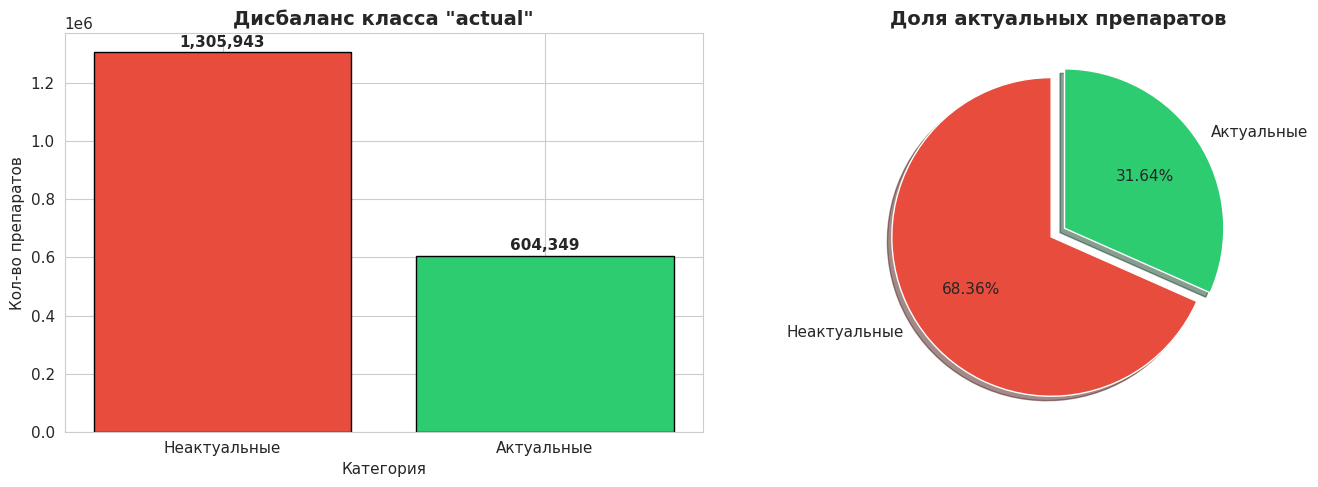

In [ ]:
query = """
SELECT 
    actual,
    COUNT(*) as count
FROM raw_data.drug_products
GROUP BY actual;
"""

df_actual = pd.read_sql(query, engine)

# Переводим boolean в читаемые подписи
df_actual['actual_label'] = df_actual['actual'].map({True: 'Актуальные', False: 'Неактуальные'})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Слева: столбчатая диаграмма 
bars = axes[0].bar(df_actual['actual_label'], df_actual['count'], color=['#e74c3c', '#2ecc71'], edgecolor='black')
axes[0].set_title(
    'Дисбаланс класса "actual"', 
    fontsize=14, 
    fontweight='bold'
)
axes[0].set_ylabel('Кол-во препаратов')
axes[0].set_xlabel('Категория')

# Добавляем подписи с числами над столбцами
for bar, count in zip(bars, df_actual['count']):
    axes[0].text(
    bar.get_x() + bar.get_width()/2,  # X-координата текста
    bar.get_height() + 20000,         # Y-координата текста
    f'{count:,}',                     # сам текст
    ha='center',                      # горизонтальное выравнивание
    fontsize=11, 
    fontweight='bold'
)

# Справа: круговая диаграмма 
axes[1].pie(
    df_actual['count'],                    # значения
    labels=df_actual['actual_label'],      # подписи
    autopct='%1.2f%%',                     # формат процентов
    startangle=90,                         # начальный угол
    colors=['#e74c3c', '#2ecc71'],     # цвета
    explode=(0.05, 0.05),                  # "отрыв" секторов
    shadow=True                            # тень
)
axes[1].set_title('Доля актуальных препаратов', fontsize=14, fontweight='bold')

plt.tight_layout() # Автоматически подгоняет отступы между графиками
# plt.savefig(f'{NOTEBOOK_DIR}/01_actual_imbalance.png', dpi=100, bbox_inches='tight')
plt.show()

### ЖНВЛП И НАРКОТИЧЕСКИЕ

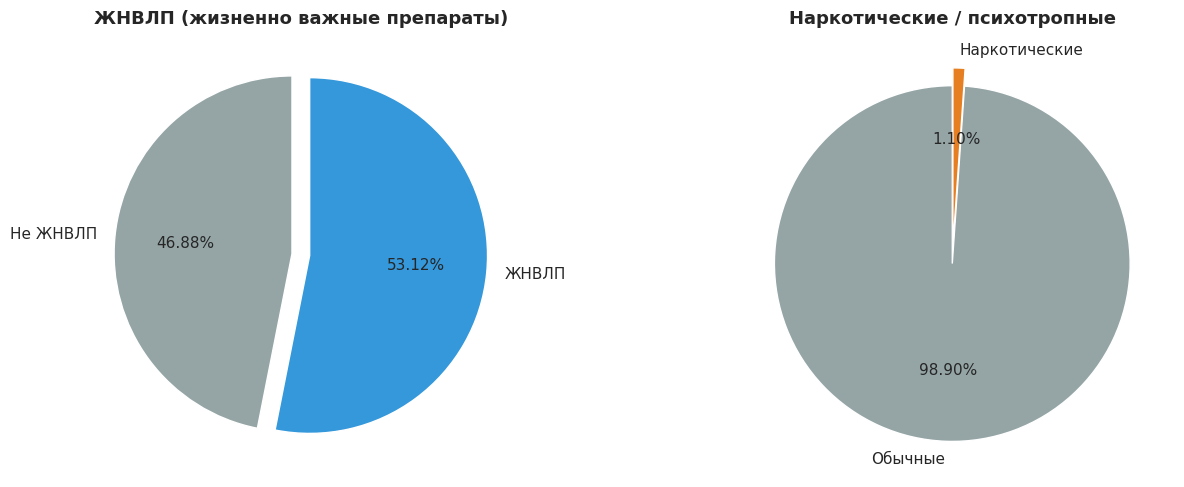

In [4]:
query = """
SELECT 
    essential_medicines,
    narcotic_psychotropic,
    COUNT(*) AS count
FROM raw_data.drug_products
GROUP BY essential_medicines, narcotic_psychotropic
"""

df_cat = pd.read_sql(query, engine)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- ЖНВЛП ---
jvnlp = df_cat.groupby('essential_medicines')['count'].sum()
axes[0].pie(
    jvnlp, 
    labels=['Не ЖНВЛП', 'ЖНВЛП'], 
    autopct='%1.2f%%',
    colors=['#95a5a6', '#3498db'], 
    startangle=90, 
    explode=(0.05, 0.05)
)

axes[0].set_title('ЖНВЛП (жизненно важные препараты)', fontsize=13, fontweight='bold')

# Наркотические 
narc = df_cat.groupby('narcotic_psychotropic')['count'].sum()
axes[1].pie(
    narc, 
    labels=['Обычные', 'Наркотические'], 
    autopct='%1.2f%%',
    colors=['#95a5a6', '#e67e22'], 
    startangle=90, 
    explode=(0.05, 0.05)
)
axes[1].set_title('Наркотические / психотропные', fontsize=13, fontweight='bold')

plt.tight_layout()
# plt.savefig(f'{NOTEBOOK_DIR}/02_categories.png', dpi=100, bbox_inches='tight')
plt.show()

# Топ стран и производителей

### ТОП-15 СТРАН

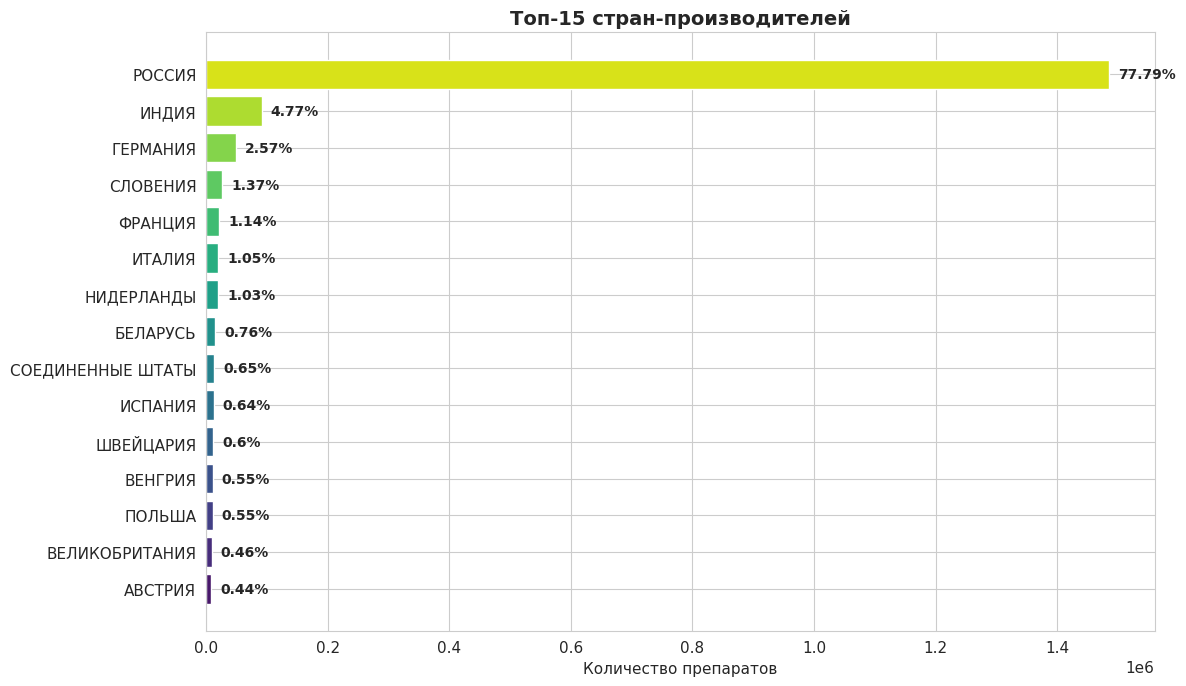

In [5]:
query = """
SELECT 
    country,
    COUNT(*) AS count,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct
FROM raw_data.drug_products
WHERE country IS NOT NULL AND country != ''
GROUP BY country
ORDER BY count DESC
LIMIT 15
"""

df_country = pd.read_sql(query, engine)

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(
    df_country['country'][::-1], 
    df_country['count'][::-1],
    color=sns.color_palette("viridis", len(df_country))
)
ax.set_xlabel('Количество препаратов')
ax.set_title('Топ-15 стран-производителей', fontsize=14, fontweight='bold')

for bar, pct in zip(bars, df_country['pct'][::-1]):
    ax.text(
        bar.get_width() + 15000, 
        bar.get_y() + bar.get_height()/2,
        f'{pct}%', 
        va='center', 
        fontsize=10, 
        fontweight='bold'
)

plt.tight_layout()
# plt.savefig(f'{NOTEBOOK_DIR}/03_top_countries.png', dpi=100, bbox_inches='tight')
plt.show()

### ТОП-15 ПРОИЗВОДИТЕЛЕЙ

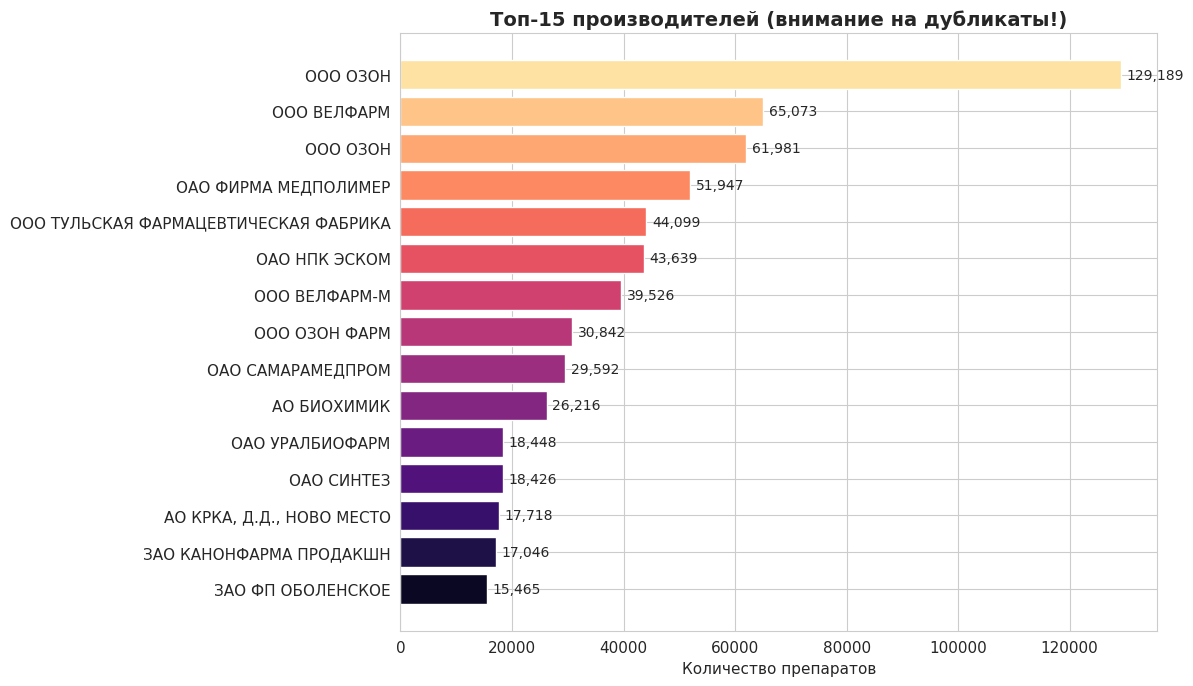

In [6]:
query = """
SELECT 
    name_producer,
    COUNT(*) AS count
FROM raw_data.drug_products
WHERE name_producer IS NOT NULL
GROUP BY name_producer
ORDER BY count DESC
LIMIT 15
"""
df_prod = pd.read_sql(query, engine)

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(
    df_prod['name_producer'][::-1], 
    df_prod['count'][::-1],
    color=sns.color_palette("magma", len(df_prod))
)
ax.set_xlabel('Количество препаратов')
ax.set_title('Топ-15 производителей (внимание на дубликаты!)', fontsize=14, fontweight='bold')

for bar, count in zip(bars, df_prod['count'][::-1]):
    ax.text(
        bar.get_width() + 1000, 
        bar.get_y() + bar.get_height()/2,
        f'{count:,}', 
        va='center', 
        fontsize=10
)

plt.tight_layout()
# plt.savefig(f'{NOTEBOOK_DIR}/04_top_producers.png', dpi=100, bbox_inches='tight')
plt.show()

# ATC-группы

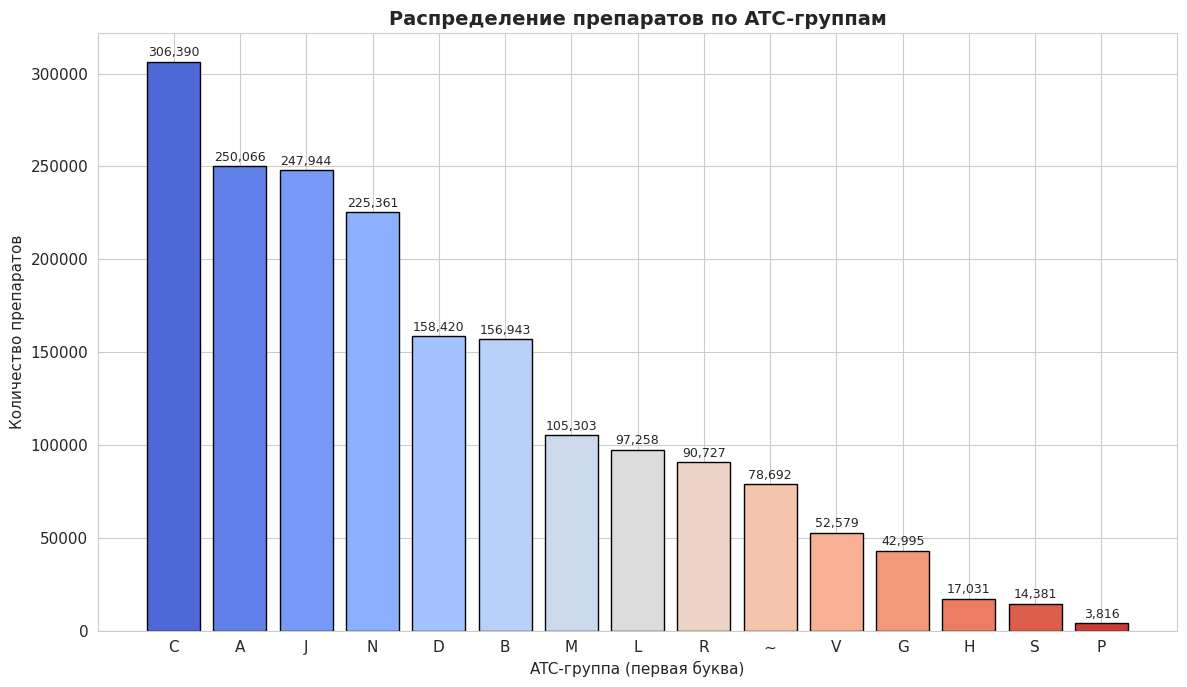


📋 Расшифровка ATC-групп:
  C — Сердечно-сосудистая: 306,390
  A — Пищеварительный тракт: 250,066
  J — Противомикробные: 247,944
  N — Нервная система: 225,361
  D — Дерматология: 158,420
  B — Кровь и кроветворение: 156,943
  M — Костно-мышечная: 105,303
  L — Противоопухолевые: 97,258
  R — Дыхательная система: 90,727
  ~ — Неизвестно: 78,692
  V — Разное: 52,579
  G — Мочеполовая система: 42,995
  H — Гормоны (кроме половых): 17,031
  S — Органы чувств: 14,381
  P — Противопаразитарные: 3,816


In [7]:
# Расшифровка ATC-групп (по классификации ВОЗ)
ATC_NAMES = {
    'A': 'Пищеварительный тракт',
    'B': 'Кровь и кроветворение',
    'C': 'Сердечно-сосудистая',
    'D': 'Дерматология',
    'G': 'Мочеполовая система',
    'H': 'Гормоны (кроме половых)',
    'J': 'Противомикробные',
    'L': 'Противоопухолевые',
    'M': 'Костно-мышечная',
    'N': 'Нервная система',
    'P': 'Противопаразитарные',
    'R': 'Дыхательная система',
    'S': 'Органы чувств',
    'V': 'Разное'
}

query = """
SELECT 
    LEFT(code_atc, 1) AS atc_letter,
    COUNT(*) AS count
FROM raw_data.drug_products
WHERE code_atc IS NOT NULL AND code_atc != '~'
GROUP BY LEFT(code_atc, 1)
ORDER BY count DESC
"""

df_atc = pd.read_sql(query, engine)
df_atc['atc_name'] = df_atc['atc_letter'].map(ATC_NAMES).fillna('Неизвестно')

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.bar(
    df_atc['atc_letter'], 
    df_atc['count'],
    color=sns.color_palette("coolwarm", len(df_atc)),
    edgecolor='black'
)
ax.set_xlabel('ATC-группа (первая буква)')
ax.set_ylabel('Количество препаратов')
ax.set_title('Распределение препаратов по ATC-группам', fontsize=14, fontweight='bold')

for bar, count in zip(bars, df_atc['count']):
    ax.text(
        bar.get_x() + bar.get_width()/2, 
        bar.get_height() + 3000,
        f'{count:,}', 
        ha='center', 
        fontsize=9
    )

plt.tight_layout()
# plt.savefig(f'{NOTEBOOK_DIR}/05_atc_groups.png', dpi=100, bbox_inches='tight')
plt.show()

# Вывод расшифровки
print("\n📋 Расшифровка ATC-групп:")
for _, row in df_atc.iterrows():
    print(f"  {row['atc_letter']} — {row['atc_name']}: {row['count']:,}")

# Временные ряды - год регистрации

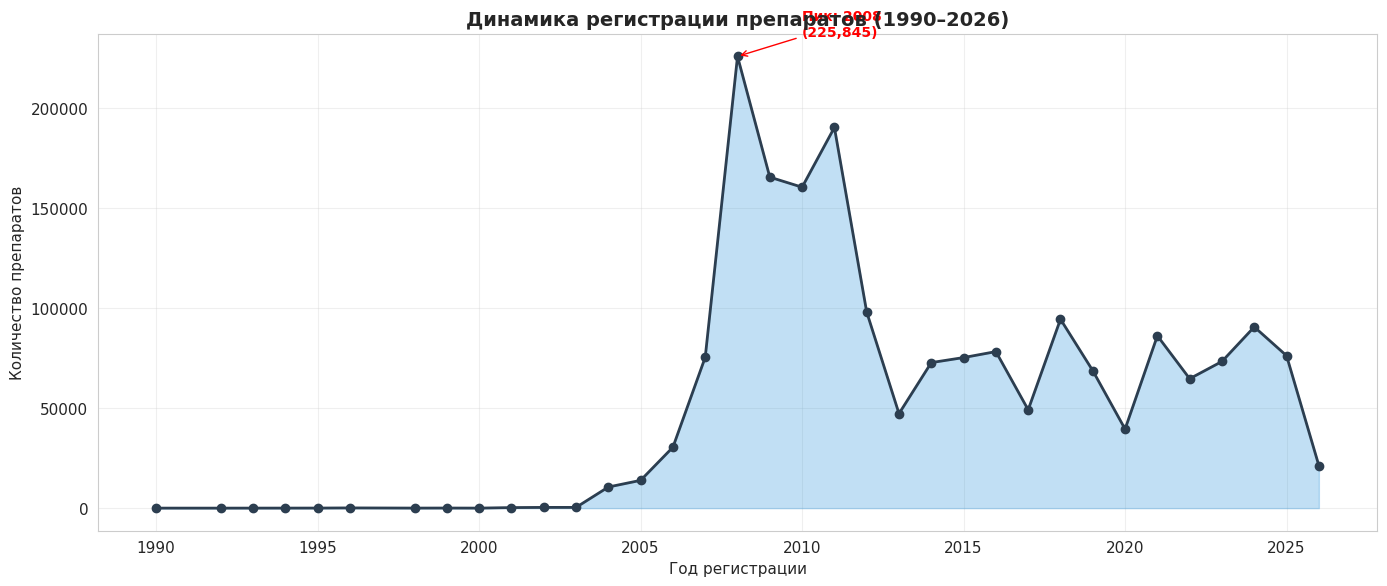

In [8]:
query = """
SELECT 
    EXTRACT(YEAR FROM date_registration)::int AS reg_year,
    COUNT(*) AS count
FROM raw_data.drug_products
WHERE date_registration IS NOT NULL
  AND EXTRACT(YEAR FROM date_registration) >= 1990
GROUP BY EXTRACT(YEAR FROM date_registration)
ORDER BY reg_year
"""

df_years = pd.read_sql(query, engine)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(
    df_years['reg_year'], 
    df_years['count'], 
    marker='o', 
    linewidth=2, 
    markersize=6, 
    color='#2c3e50'
)
ax.fill_between(df_years['reg_year'], df_years['count'], alpha=0.3, color='#3498db')
ax.set_xlabel('Год регистрации')
ax.set_ylabel('Количество препаратов')
ax.set_title('Динамика регистрации препаратов (1990–2026)', 
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)

# Отмечаем пики
max_year = df_years.loc[df_years['count'].idxmax()]
ax.annotate(f'Пик: {int(max_year["reg_year"])}\n({max_year["count"]:,})',
            xy=(max_year['reg_year'], max_year['count']),
            xytext=(max_year['reg_year'] + 2, max_year['count'] + 10000),
            arrowprops=dict(arrowstyle='->', color='red'),
            fontsize=10, color='red', fontweight='bold')

plt.tight_layout()
# plt.savefig(f'{NOTEBOOK_DIR}/06_registration_trend.png', dpi=100, bbox_inches='tight')
plt.show()